In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,GridSearchCV,cross_val_score
from sklearn.tree import DecisionTreeRegressor,DecisionTreeClassifier
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import r2_score,accuracy_score
from sklearn.datasets import load_iris

In [39]:
df=pd.DataFrame(load_iris(return_X_y=False).data,columns=load_iris(return_X_y=False).feature_names)
df['target']=load_iris(return_X_y=False).target

In [40]:
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [41]:
X=df.iloc[:,1:3]
y=df.iloc[:,-1]
y=y[y!=0]
df_new=pd.concat([X,y],axis=1)

In [42]:
df_new.dropna(inplace=True)

In [43]:
df_new

,sepal width (cm),petal length (cm),target
50,3.2,4.7,1.0
51,3.2,4.5,1.0
52,3.1,4.9,1.0
53,2.3,4.0,1.0
54,2.8,4.6,1.0
...,...,...,...
145,3.0,5.2,2.0
146,2.5,5.0,2.0
147,3.0,5.2,2.0
148,3.4,5.4,2.0


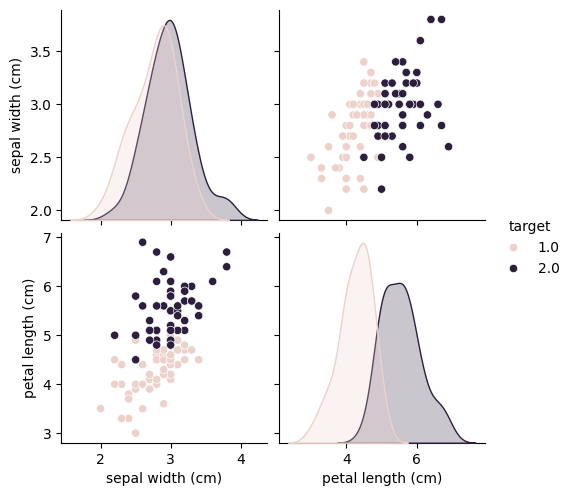

In [28]:
import seaborn as sns
sns.pairplot(df_new,hue='target')

In [44]:
df_new=df_new.sample(df_new.shape[0])
df_train=df_new.iloc[:int(df_new.shape[0]*0.6),:].sample(10)
df_val=df_new.iloc[int(df_new.shape[0]*0.6):int(df_new.shape[0]*0.8),:].sample(5)
df_test=df_new.iloc[int(df_new.shape[0]*0.8):,:].sample(5)

In [45]:
df_val

,sepal width (cm),petal length (cm),target
97,2.9,4.3,1.0
145,3.0,5.2,2.0
107,2.9,6.3,2.0
81,2.4,3.7,1.0
132,2.8,5.6,2.0


In [46]:
x_test,y_test=df_test.iloc[:,:2],df_test.iloc[:,-1]

In [63]:
n=3
model=[]
for i in range(n):
  df_bag=df_train.sample(8,replace=True)
  x_train=df_bag.iloc[:,:2]
  y_train=df_bag.iloc[:,-1]
  x_test=df_val.iloc[:,:2]
  y_test=df_val.iloc[:,-1]
  dt_bag=DecisionTreeClassifier()
  dt_bag.fit(x_train,y_train)
  model.append(dt_bag)
  print(accuracy_score(y_test,dt_bag.predict(x_test)))

0.4
0.8
0.8


In [64]:
n=3
for i in range(n):
  x_test=df_test.iloc[:,:2]
  y_test=df_test.iloc[:,-1]
  print(accuracy_score(y_test,model[i].predict(x_test)))

0.4
0.6
0.6
